In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sb
import pandas as pd

# **1**

1. Сгенерировать реализацию выборки из распределения N[2, 4] размера 50, вывести
на экран первые 5 значений.
2. Найти выборочное среднее, стандартное отклонение, медиану.
3. Построить гистограмму.
4. Построить график плотности и функции распредления.

In [2]:
x=np.random.normal(loc=2.0, scale=4.0, size=50)
x[:5]

array([1.88203538e+00, 1.71332355e-03, 1.92160758e+00, 1.04815616e+01,
       1.24903894e+00])

In [3]:
x.mean()

np.float64(2.2222929906209696)

In [4]:
np.std(x)

np.float64(3.713127966368379)

In [5]:
np.median(x)

np.float64(1.9018214780844362)

/tmp/ipykernel_2216/1697046444.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sb.distplot(x)


<Axes: ylabel='Density'>

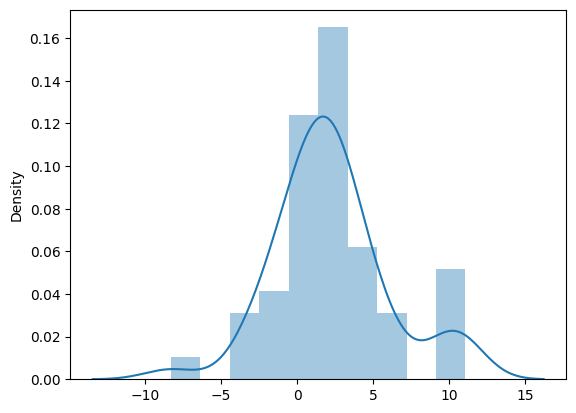

In [6]:
sb.distplot(x)

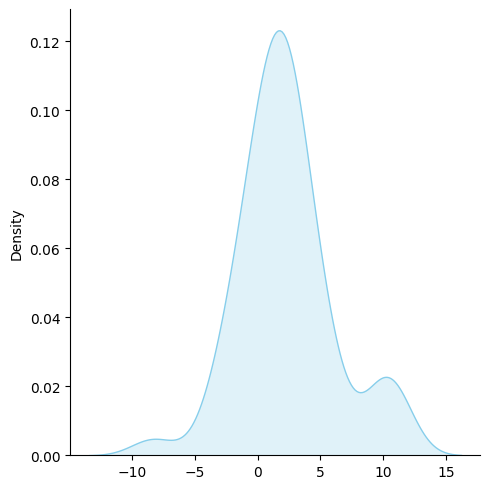

In [7]:
sb.displot(x, kind='kde', color='skyblue', fill=True)
plt.show()

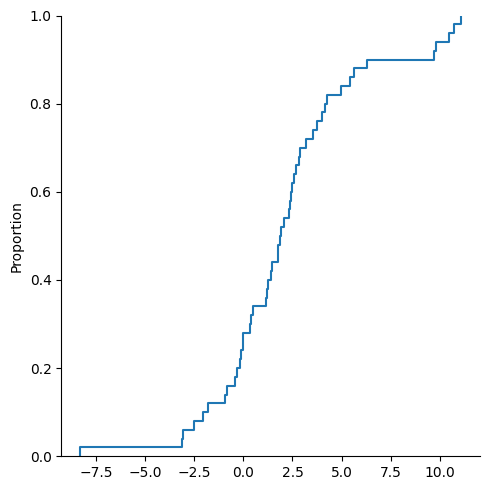

In [8]:
sb.displot(x, kind='ecdf')
plt.show()

# **1.1. **

Проделать следующие операции с массивом данных "flights":
1) вывести количество столбцов и строк;
2) вывести название третьего столбца;
3) вывести, сколько было пассажиров в июне 1952;
4) создать DataFrame из строк, в которых число перевезенных пассажиров не меньше 165;
5) создать DataFrame для 1951–1953 годов;

6*) найти суммарное число пассажиров за каждый год.

7*) создать DataFrame, в котором столбцами будут названия месяцев (данные – число пассажиров, строки
– год);

In [9]:
flights=sb.load_dataset("flights")
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [10]:
flights.shape

(144, 3)

In [11]:
list(flights.columns.values)[2]

'passengers'

In [12]:
len(flights.loc[(flights['month']=='Jun') & (flights['year']==1952)])

1

In [13]:
flight165=flights.loc[flights['passengers']>=165]
flight165

,year,month,passengers
18,1950,Jul,170
19,1950,Aug,170
26,1951,Mar,178
28,1951,May,172
29,1951,Jun,178
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [14]:
flightYear=flights.loc[(flights['year']>=1951) & (flights['year']<=1953)]

In [15]:
flights.groupby('year')['passengers'].sum()

,passengers
year,
1949,1520
1950,1676
1951,2042
1952,2364
1953,2700
1954,2867
1955,3408
1956,3939
1957,4421


In [16]:
flights.groupby('month')['passengers'].sum().index.tolist()

/tmp/ipykernel_2216/3909816627.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  flights.groupby('month')['passengers'].sum().index.tolist()


['Jan',
 'Feb',
 'Mar',
 'Apr',
 'May',
 'Jun',
 'Jul',
 'Aug',
 'Sep',
 'Oct',
 'Nov',
 'Dec']

In [17]:
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [18]:
z=flights.pivot(index='month', columns='year', values='passengers')
z

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112,115,145,171,196,204,242,284,315,340,360,417
Feb,118,126,150,180,196,188,233,277,301,318,342,391
Mar,132,141,178,193,236,235,267,317,356,362,406,419
Apr,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472
Jun,135,149,178,218,243,264,315,374,422,435,472,535
Jul,148,170,199,230,264,302,364,413,465,491,548,622
Aug,148,170,199,242,272,293,347,405,467,505,559,606
Sep,136,158,184,209,237,259,312,355,404,404,463,508


# **1.2. **

Для массива данных "flights"
1) построить столбцовую диаграмму числа перевезенных пассажиров за 1952 год;
2) построить столбцовые диаграммы для разных лет, сравнить;
3) построить столбцовую диаграмму числа перевезенных пассажиров в марте;
4) сравнить 1951–1955 годы с помощью параллельных координат.

In [19]:
fligths1952=flights.loc[ flights['year']==1952]
fligths1952

,year,month,passengers
36,1952,Jan,171
37,1952,Feb,180
38,1952,Mar,193
39,1952,Apr,181
40,1952,May,183
41,1952,Jun,218
42,1952,Jul,230
43,1952,Aug,242
44,1952,Sep,209
45,1952,Oct,191


/tmp/ipykernel_2216/2349918697.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  passengers = fligths1952.groupby("month").agg({"passengers": "mean"})


<BarContainer object of 12 artists>

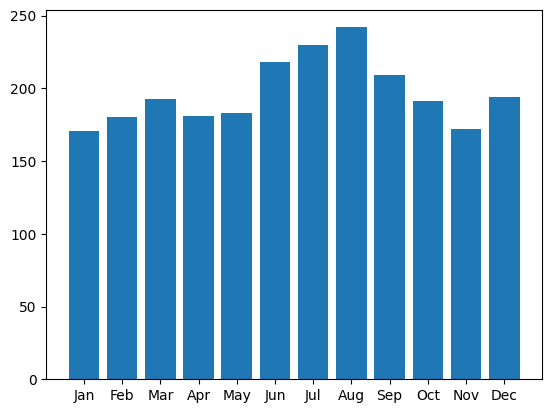

In [20]:
passengers = fligths1952.groupby("month").agg({"passengers": "mean"})
plt.bar(fligths1952['month'].values, passengers['passengers'])

/tmp/ipykernel_2216/664951124.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  passengers = flightsyear.groupby("month").agg({"passengers": "mean"})


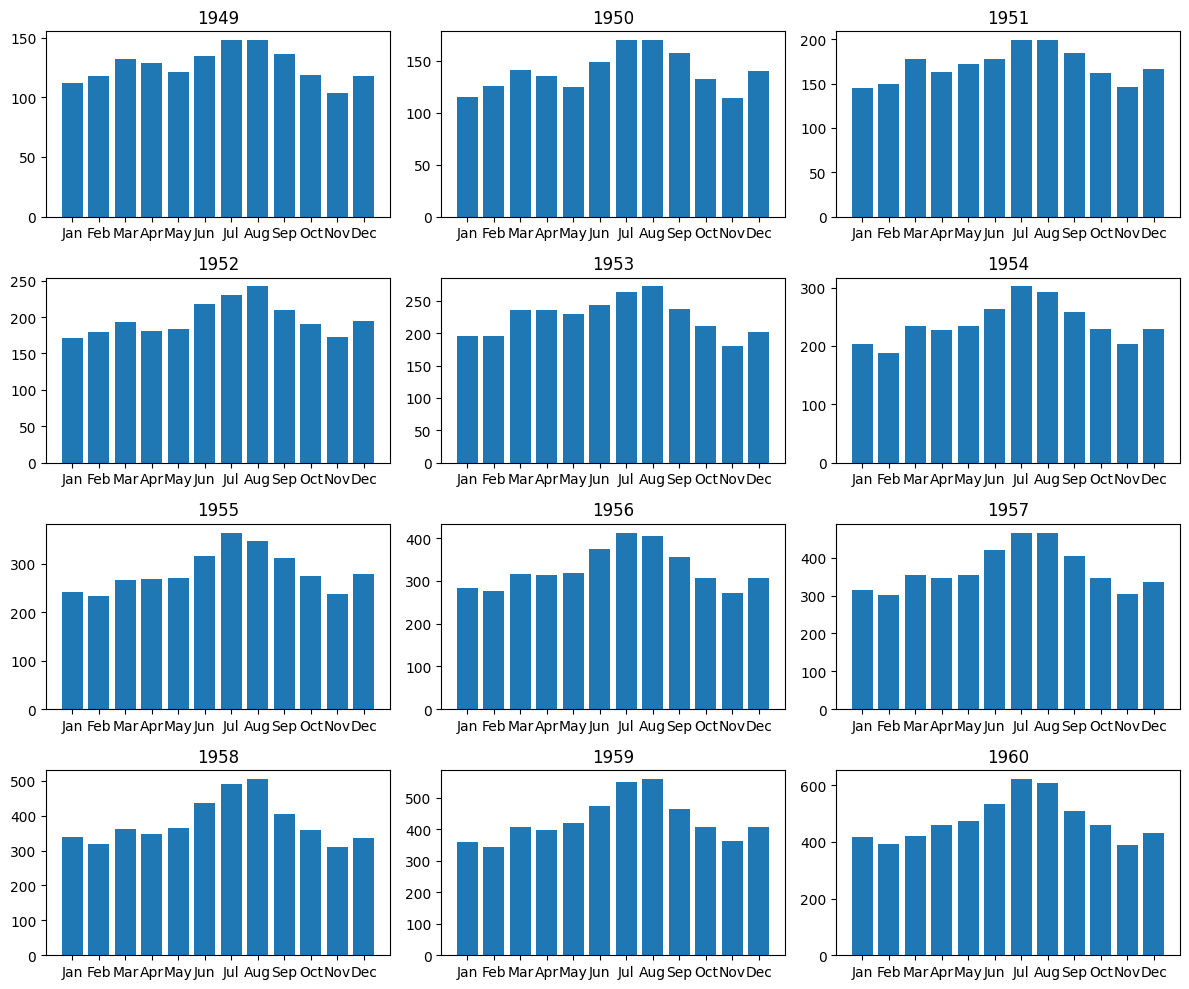

In [21]:
years = [x for x in range(1949,1961)]
fig = plt.figure(figsize=(12, 10))
for year in years:
  flightsyear=flights.loc[ flights['year']==year]
  passengers = flightsyear.groupby("month").agg({"passengers": "mean"})
  plt.subplot(4, 3, year-1948)
  plt.bar(flightsyear['month'].values, passengers['passengers'])
  plt.title(year)
plt.tight_layout()
plt.show()


<BarContainer object of 12 artists>

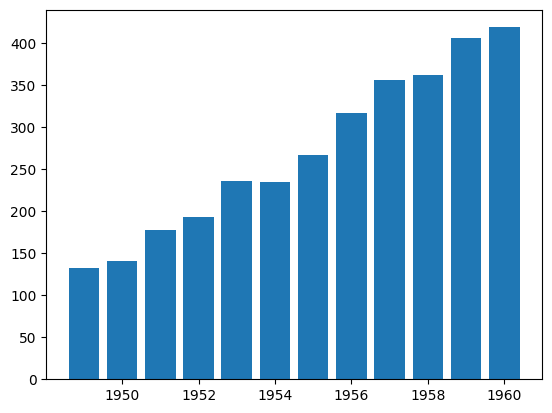

In [22]:
fligthsmarch=flights.loc[ flights['month']=='Mar']
passengers = fligthsmarch.groupby("year").agg({"passengers": "mean"})
plt.bar(fligthsmarch['year'].values, passengers['passengers'])


In [23]:
from pandas.plotting import parallel_coordinates

In [24]:
flightYear=flights.loc[(flights['year']>=1951) & (flights['year']<=1955)]
month_mapping = {
    'Jan': '1', 'Feb': '2', 'Mar': '3', 'Apr': '4',
    'May': '5', 'Jun': '6', 'Jul': '7', 'Aug': '8',
    'Sep': '9', 'Oct': '10', 'Nov': '11', 'Dec': '12'
}
flightYear['month_number'] = flightYear['month'].map(month_mapping)
flightYear=flightYear.drop('month',axis=1)
flightYear=flightYear.astype(int)

/tmp/ipykernel_2216/1268801567.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  flightYear['month_number'] = flightYear['month'].map(month_mapping)


<Axes: >

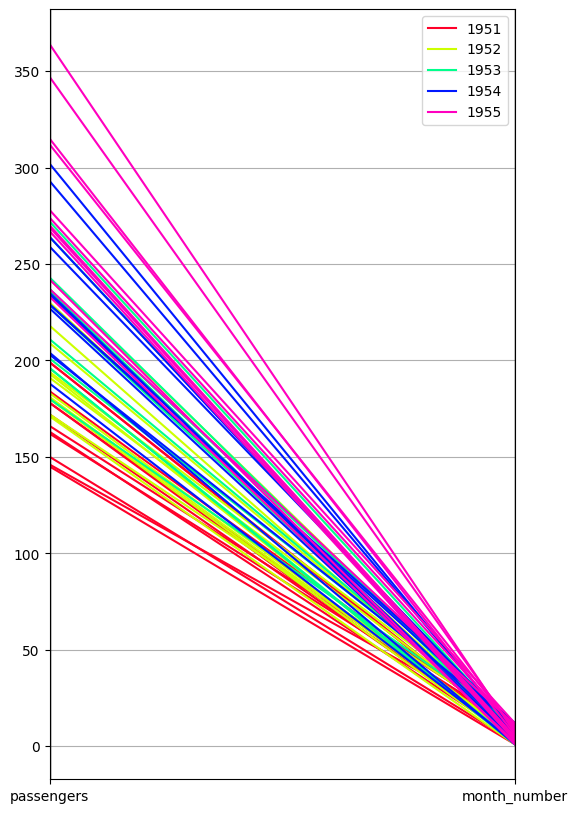

In [25]:
plt.figure(figsize=(6, 10))
parallel_coordinates(flightYear, 'year', colormap='gist_rainbow')

# **1.3. **

Независимые с.в. X, Y, Z ⇠ N (0, 1). Построить диаграммы рассеяния для реализаций (X  Y, Y ) и
(X Y, Z), сравнить.

Построить одну диаграмму рассеяния для реализаций этих векторов, раскрасив точки
в два цвета.

Построить также ядерные оценки двумерных плотностей (kdplot()) для реализаций этих векторов и сравнить.

In [26]:
X=np.random.normal(loc=0.0, scale=1.0, size=200)
Y=np.random.normal(loc=0.0, scale=1.0, size=200)
Z=np.random.normal(loc=0.0, scale=1.0, size=200)

In [27]:
XY = X * Y

[Text(0.5, 1.0, '(XY, Z)'), Text(0.5, 0, 'XY'), Text(0, 0.5, 'Z')]

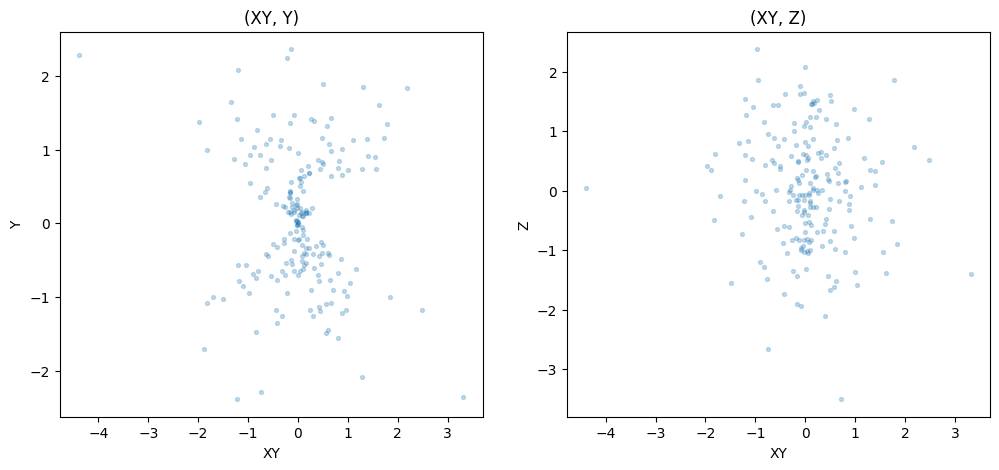

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(XY, Y, s=8, alpha=0.25)
axes[0].set(title="(XY, Y)", xlabel="XY", ylabel="Y")

axes[1].scatter(XY, Z, s=8, alpha=0.25)
axes[1].set(title="(XY, Z)", xlabel="XY", ylabel="Z")

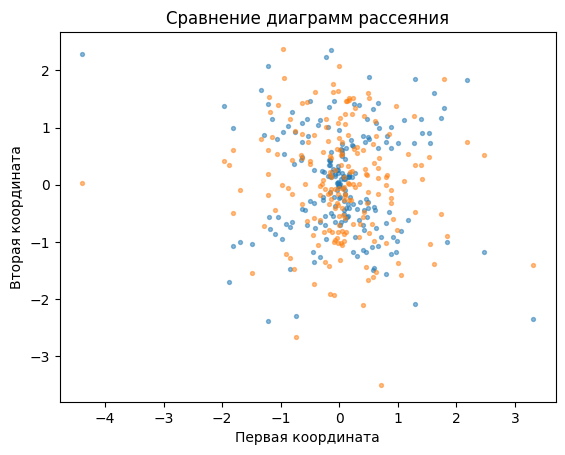

In [29]:
plt.scatter(XY, Y, s=8, alpha=0.5, label="(XY, Y)")
plt.scatter(XY, Z, s=8, alpha=0.5, label="(XY, Z)")
plt.xlabel("Первая координата")
plt.ylabel("Вторая координата")
plt.title("Сравнение диаграмм рассеяния")
plt.show()

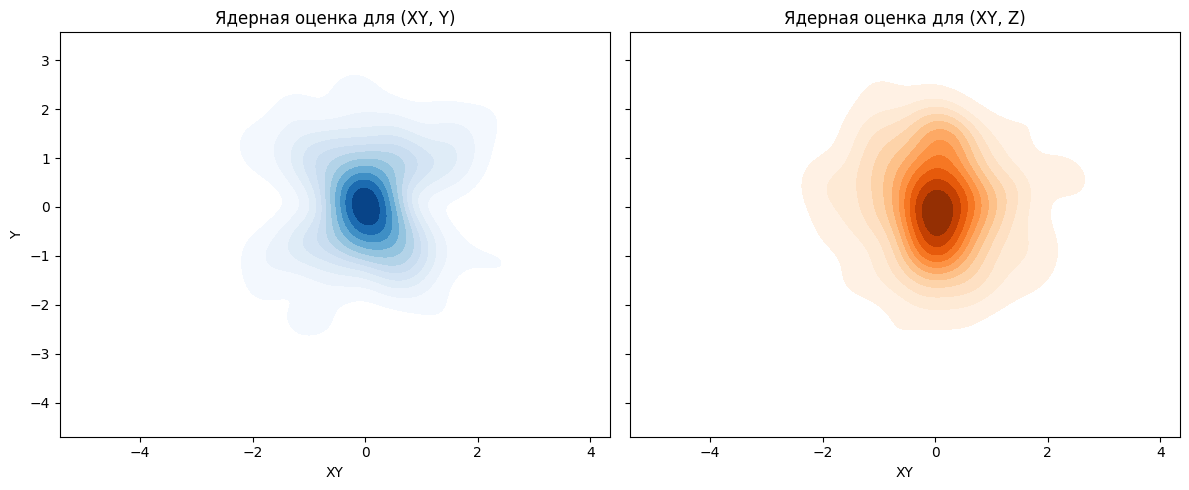

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

sb.kdeplot(x=XY, y=Y, fill=True, levels=12, cmap="Blues", ax=axes[0])
axes[0].set(title="Ядерная оценка для (XY, Y)", xlabel="XY", ylabel="Y")

sb.kdeplot(x=XY, y=Z, fill=True, levels=12, cmap="Oranges", ax=axes[1])
axes[1].set(title="Ядерная оценка для (XY, Z)", xlabel="XY", ylabel="Z")

plt.tight_layout()
plt.show()